# Escalonamento Multidimensional (ESM) — Indicadores econômicos e sociais do Banco Mundial
### Países agrupados por nível de renda 

**Dados:** 8 indicadores de 2019 para 155 países (World Bank Open Data, https://data.worldbank.org).

| Variável | Indicador do Banco Mundial | Descrição |
|---|---|---|
| `pib_pc` | NY.GDP.PCAP.PP.KD | PIB per capita (PPC, US$ constantes) |
| `expec_vida` | SP.DYN.LE00.IN | Expectativa de vida ao nascer (anos) |
| `mort_infantil` | SP.DYN.IMRT.IN | Mortalidade infantil (por 1.000 nascidos vivos) |
| `urbana` | SP.URB.TOTL.IN.ZS | População urbana (% do total) |
| `comercio` | NE.TRD.GNFS.ZS | Comércio exterior (% do PIB) |
| `inflacao` | FP.CPI.TOTL.ZG | Inflação anual (%) |
| `desemprego` | SL.UEM.TOTL.ZS | Desemprego (% da força de trabalho) |
| `saude_pib` | SH.XPD.CHEX.GD.ZS | Gasto em saúde (% do PIB) |

As variáveis têm escalas muito diferentes (dólares × percentuais), então trabalharemos com as variáveis **padronizadas** (equivale a usar a matriz de correlações).

**Roteiro:** (1) dados → (2) análise descritiva → (3) componentes principais → (4) ESM com $q=2$ e $q=3$ → (5) ESM × ACP → (6) comentários.

## 0. Pacotes

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(suppress=True, precision=4)
pd.options.display.float_format = "{:,.4f}".format

## 1. Dados

Tentamos baixar os dados diretamente da API do Banco Mundial. Se a API estiver indisponível, usamos o arquivo `bancomundial_2019.csv` (cópia dos dados, mantida para a aula ser reproduzível). Mantemos apenas os países com **todos** os indicadores disponíveis.

In [2]:
INDICADORES = {
    "NY.GDP.PCAP.PP.KD": "pib_pc",
    "SP.DYN.LE00.IN":    "expec_vida",
    "SP.DYN.IMRT.IN":    "mort_infantil",
    "SP.URB.TOTL.IN.ZS": "urbana",
    "NE.TRD.GNFS.ZS":    "comercio",
    "FP.CPI.TOTL.ZG":    "inflacao",
    "SL.UEM.TOTL.ZS":    "desemprego",
    "SH.XPD.CHEX.GD.ZS": "saude_pib",
}
ANO = 2019

def baixar_banco_mundial():
    import json, urllib.request
    def get(url):
        return json.load(urllib.request.urlopen(url, timeout=20))
    cols = {}
    for cod, nome in INDICADORES.items():
        d = get(f"https://api.worldbank.org/v2/country/all/indicator/{cod}?date={ANO}&format=json&per_page=400")
        cols[nome] = {r["countryiso3code"]: r["value"] for r in d[1] if r["countryiso3code"]}
    meta = get("https://api.worldbank.org/v2/country?format=json&per_page=400")[1]
    meta = pd.DataFrame([{"iso3": c["id"], "pais": c["name"], "regiao": c["region"]["value"].strip(),
                          "renda": c["incomeLevel"]["value"]}
                         for c in meta if c["region"]["value"] != "Aggregates"]).set_index("iso3")
    return meta.join(pd.DataFrame(cols), how="inner").dropna()

if os.path.exists("bancomundial_2019.csv"):
    dados = pd.read_csv("bancomundial_2019.csv", index_col=0)
else:
    try:
        dados = baixar_banco_mundial()
        dados.to_csv("bancomundial_2019.csv")
    except Exception as e:
        print("API indisponível:", e)
        from google.colab import files       # envie bancomundial_2019.csv
        files.upload()
        dados = pd.read_csv("bancomundial_2019.csv", index_col=0)

dados["regiao"] = dados["regiao"].str.strip()
print(dados.shape)
dados.head()

(155, 11)


,pais,regiao,renda,pib_pc,expec_vida,mort_infantil,urbana,comercio,inflacao,desemprego,saude_pib
AGO,Angola,Sub-Saharan Africa,Lower middle income,"9,712.9794",63.0510,35.5000,66.6638,60.3713,17.0810,16.4970,2.2039
ALB,Albania,Europe & Central Asia,Upper middle income,"16,761.1230",79.4670,8.0000,56.7639,75.3821,1.4111,11.4660,6.7814
ARE,United Arab Emirates,"Middle East, North Africa, Afghanistan & Pakistan",High income,"72,822.9466",82.5960,5.0000,85.0298,163.8221,-1.9311,2.3310,4.4029
ARG,Argentina,Latin America & Caribbean,Upper middle income,"26,629.5529",76.8470,8.9000,91.8568,32.6306,53.5483,9.8430,10.1191
ARM,Armenia,Europe & Central Asia,Upper middle income,"16,215.3608",76.2220,10.7000,65.0047,97.8470,1.4434,18.3040,11.3798


In [3]:
vars_ = list(INDICADORES.values())
ordem_renda = ["Low income", "Lower middle income", "Upper middle income", "High income"]
dados["renda"] = pd.Categorical(dados["renda"], categories=ordem_renda, ordered=True)
print(dados["renda"].value_counts().sort_index().to_string())

renda
Low income             16
Lower middle income    41
Upper middle income    46
High income            52


## 2. Análise descritiva
### 2.1 Medidas resumo

In [4]:
X = dados[vars_]
resumo = pd.DataFrame({
    "Média": X.mean(), "Variância": X.var(), "DP": X.std(),
    "CV(%)": 100 * X.std() / X.mean(),
    "Mínimo": X.min(), "Mediana": X.median(), "Máximo": X.max(),
    "Assimetria": X.apply(stats.skew), "Curtose": X.apply(lambda c: stats.kurtosis(c, fisher=False)),
}).T
resumo.round(2)

,pib_pc,expec_vida,mort_infantil,urbana,comercio,inflacao,desemprego,saude_pib
Média,"25,727.5400",72.9300,19.5800,61.2400,86.2700,5.5600,7.1800,6.3500
Variância,"655,829,197.3300",65.0300,386.3900,470.2500,"2,887.8800",460.6200,32.4300,8.0500
DP,"25,609.1600",8.0600,19.6600,21.6900,53.7400,21.4600,5.6900,2.8400
CV(%),99.5400,11.0600,100.4000,35.4100,62.2900,386.1800,79.3000,44.6700
Mínimo,"1,145.1000",31.5300,1.8000,16.1400,26.1200,-3.2300,0.1000,2.1300
Mediana,"15,790.7000",74.2100,12.6000,63.5200,76.0000,2.2500,5.0200,5.7500
Máximo,"132,724.7500",84.3600,128.9000,100.0000,382.6600,255.3000,28.4700,21.9200
Assimetria,1.5900,-1.1300,1.8200,-0.2600,2.5800,10.4200,1.6200,1.4900
Curtose,5.7500,6.0900,8.1600,2.1200,12.4500,120.1800,5.5700,8.1400


Note a forte assimetria do `pib_pc` e da `inflacao` (assimetria alta e curtose elevada). Para o PIB per capita é usual trabalhar em **escala logarítmica**; a inflação tem valores extremos (outliers).

In [5]:
# Transformação: log do PIB per capita (reduz a assimetria)
dados["log_pib_pc"] = np.log(dados["pib_pc"])
print("Assimetria pib_pc:", round(stats.skew(dados["pib_pc"]), 2),
      "| log(pib_pc):", round(stats.skew(dados["log_pib_pc"]), 2))

vars_an = ["log_pib_pc"] + [v for v in vars_ if v != "pib_pc"]    # variáveis usadas na análise
X = dados[vars_an]

Assimetria pib_pc: 1.59 | log(pib_pc): -0.22


### 2.2 Distribuições: boxplots, histogramas e QQ-plots

C:\Users\Antonio\AppData\Local\Temp\ipykernel_231132\17357198.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([Z[c] for c in Z.columns], vert=False, tick_labels=Z.columns)


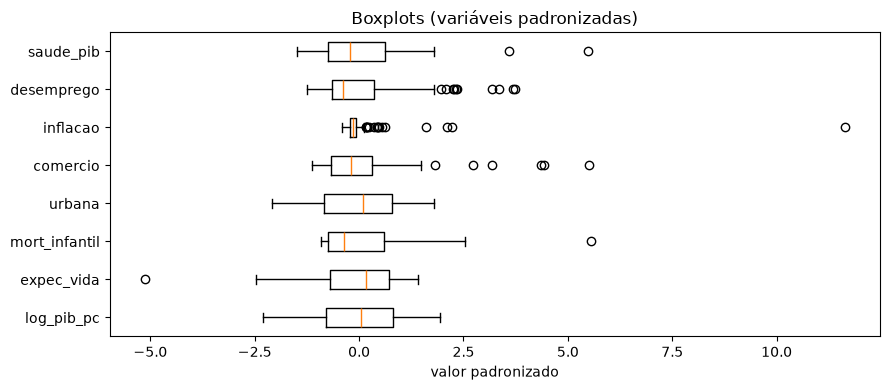

In [6]:
Z = (X - X.mean()) / X.std()                      # variáveis padronizadas
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([Z[c] for c in Z.columns], vert=False, tick_labels=Z.columns)
ax.set_xlabel("valor padronizado"); ax.set_title("Boxplots (variáveis padronizadas)")
plt.tight_layout(); plt.show()

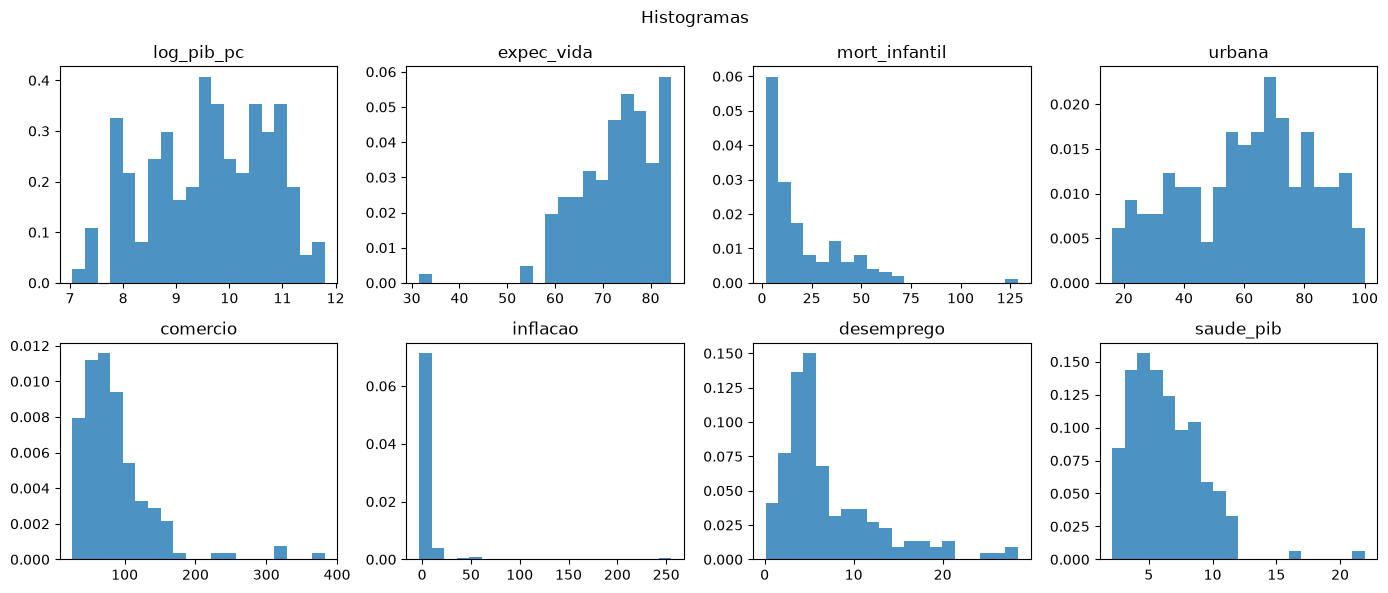

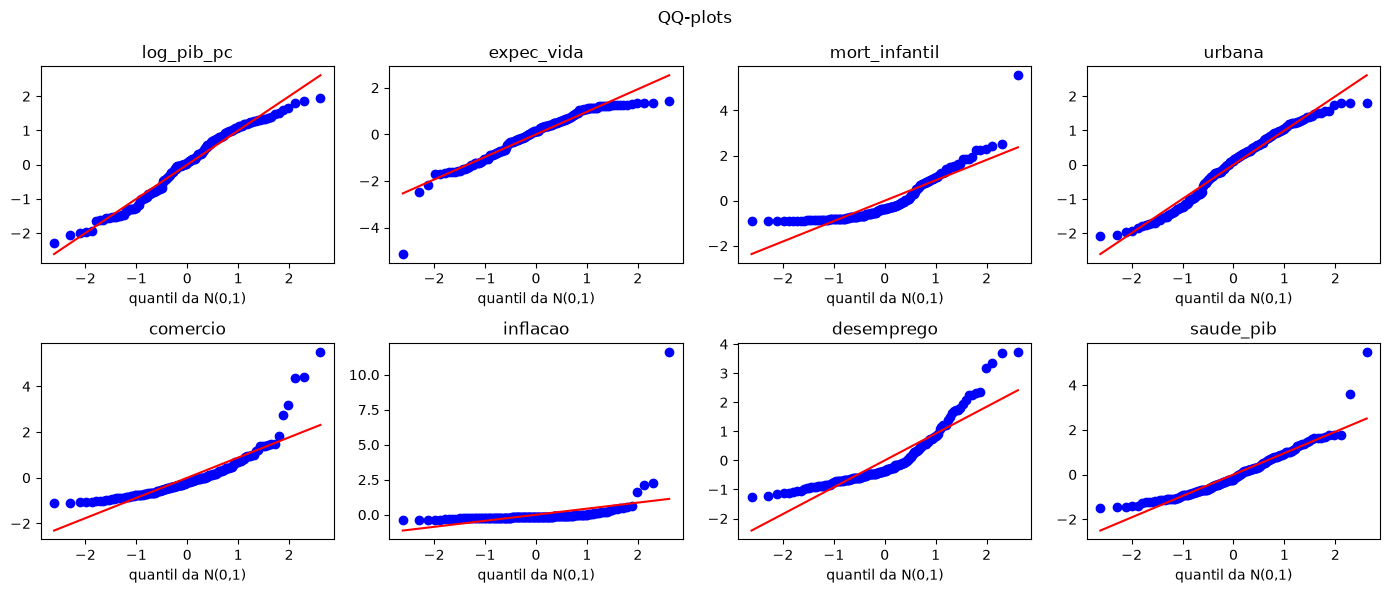

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axs.ravel(), vars_an):
    ax.hist(X[c], bins=20, density=True, color="tab:blue", alpha=0.8)
    ax.set_title(c)
plt.suptitle("Histogramas"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axs.ravel(), vars_an):
    stats.probplot(Z[c], dist="norm", plot=ax)
    ax.set_title(c); ax.set_xlabel("quantil da N(0,1)"); ax.set_ylabel("")
plt.suptitle("QQ-plots"); plt.tight_layout(); plt.show()

### 2.3 Dispersão e correlações

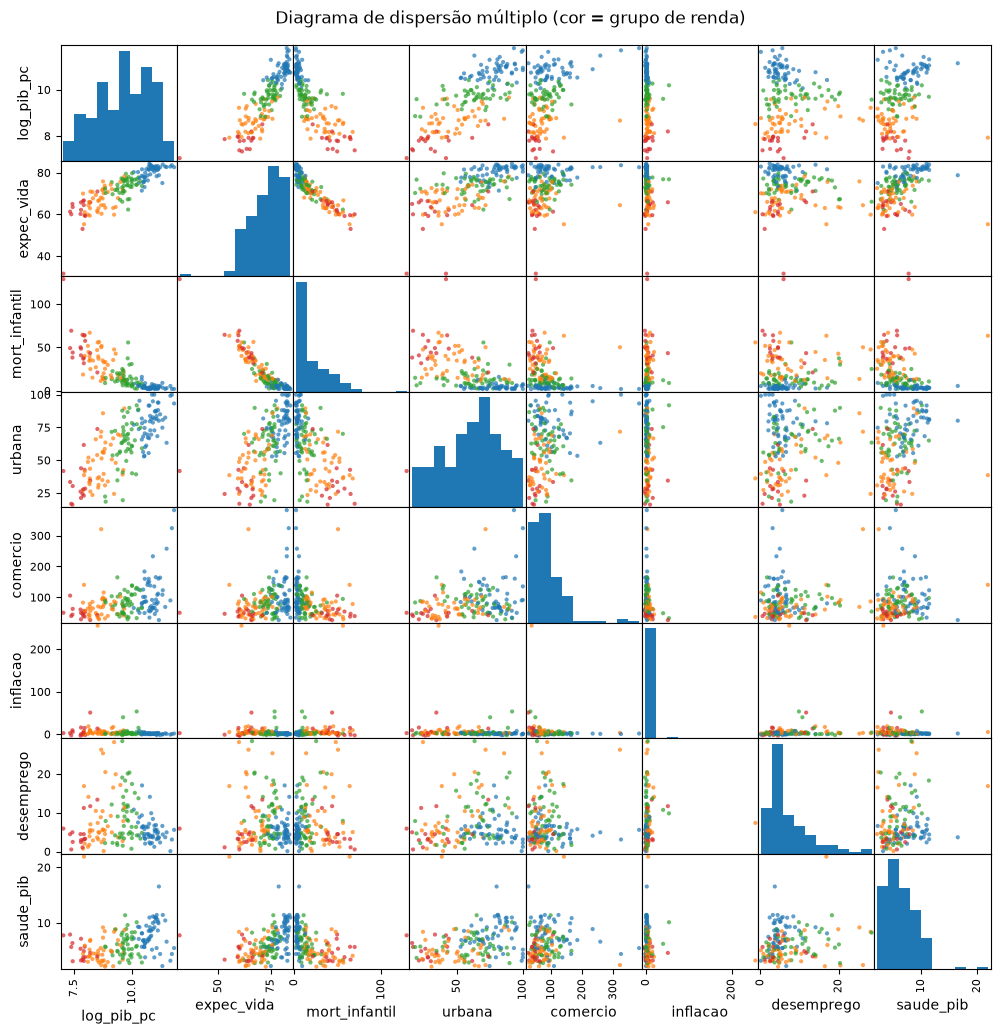

In [8]:
cores = dict(zip(ordem_renda, ["tab:red", "tab:orange", "tab:green", "tab:blue"]))
pd.plotting.scatter_matrix(X, c=dados["renda"].map(cores).astype(str), figsize=(12, 12), diagonal="hist", alpha=0.7)
plt.suptitle("Diagrama de dispersão múltiplo (cor = grupo de renda)", y=0.91)
plt.show()

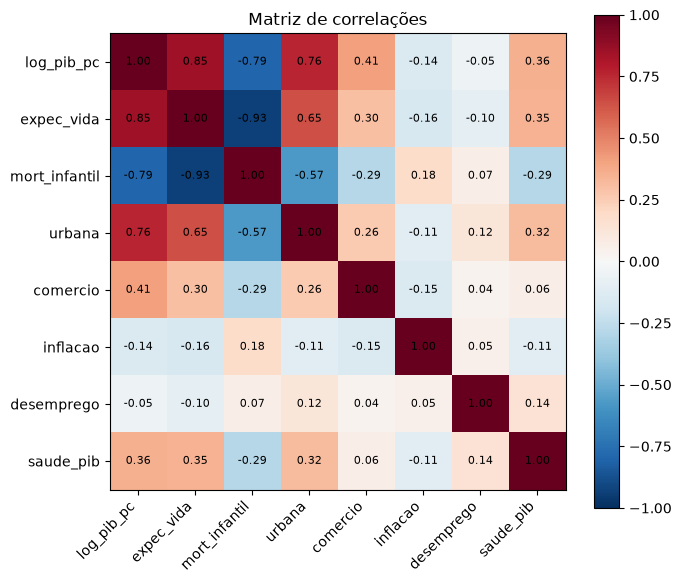

In [9]:
R = X.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_an)), vars_an, rotation=45, ha="right")
ax.set_yticks(range(len(vars_an)), vars_an)
for i in range(len(vars_an)):
    for j in range(len(vars_an)):
        ax.text(j, i, f"{R.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Matriz de correlações"); plt.tight_layout(); plt.show()

## 3. Análise de Componentes Principais (ACP)

Autovalores e autovetores da **matriz de correlações** $R$. Vamos usá-la depois para comparar com o ESM.

In [10]:
autoval, autovet = np.linalg.eigh(R.to_numpy())
o = np.argsort(autoval)[::-1]
autoval, autovet = autoval[o], autovet[:, o]
# sinal: fixa o sinal de cada componente para a soma dos coeficientes ser positiva em PC1 (conveniência)
for k in range(autovet.shape[1]):
    if autovet[:, k].sum() < 0:
        autovet[:, k] *= -1

tab = pd.DataFrame({"Autovalor": autoval,
                    "PVE (%)": 100 * autoval / autoval.sum(),
                    "PVEA (%)": 100 * np.cumsum(autoval) / autoval.sum()},
                   index=[f"Comp. {i+1}" for i in range(len(autoval))])
tab.round(2)

,Autovalor,PVE (%),PVEA (%)
Comp. 1,3.6600,45.7100,45.7100
Comp. 2,1.1400,14.2300,59.9400
Comp. 3,0.9800,12.2900,72.2200
Comp. 4,0.9100,11.3600,83.5900
Comp. 5,0.6700,8.3900,91.9800
Comp. 6,0.4500,5.6400,97.6200
Comp. 7,0.1300,1.6800,99.3000
Comp. 8,0.0600,0.7000,100.0000


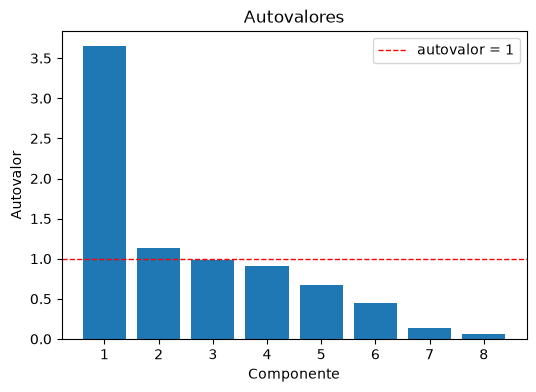

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, len(autoval) + 1), autoval)
ax.axhline(1, color="r", ls="--", lw=1, label="autovalor = 1")
ax.set_xlabel("Componente"); ax.set_ylabel("Autovalor"); ax.legend(); ax.set_title("Autovalores")
plt.show()

In [12]:
# Coeficientes e correlações entre componentes e variáveis (slide 43)
coef = pd.DataFrame(autovet[:, :2], index=vars_an, columns=["Y1 (coef.)", "Y2 (coef.)"])
corr_cv = coef.to_numpy() * np.sqrt(autoval[:2])
coef["Y1 (corr.)"], coef["Y2 (corr.)"] = corr_cv[:, 0], corr_cv[:, 1]
coef[["Y1 (coef.)", "Y1 (corr.)", "Y2 (coef.)", "Y2 (corr.)"]].round(2)

,Y1 (coef.),Y1 (corr.),Y2 (coef.),Y2 (corr.)
log_pib_pc,0.4900,0.9400,-0.0400,-0.0400
expec_vida,0.4900,0.9300,-0.1100,-0.1200
mort_infantil,-0.4700,-0.9000,0.1300,0.1300
urbana,0.4200,0.8000,0.1900,0.2000
comercio,0.2300,0.4500,-0.0800,-0.0800
inflacao,-0.1300,-0.2400,0.2300,0.2500
desemprego,-0.0100,-0.0100,0.8300,0.8800
saude_pib,0.2400,0.4600,0.4300,0.4600


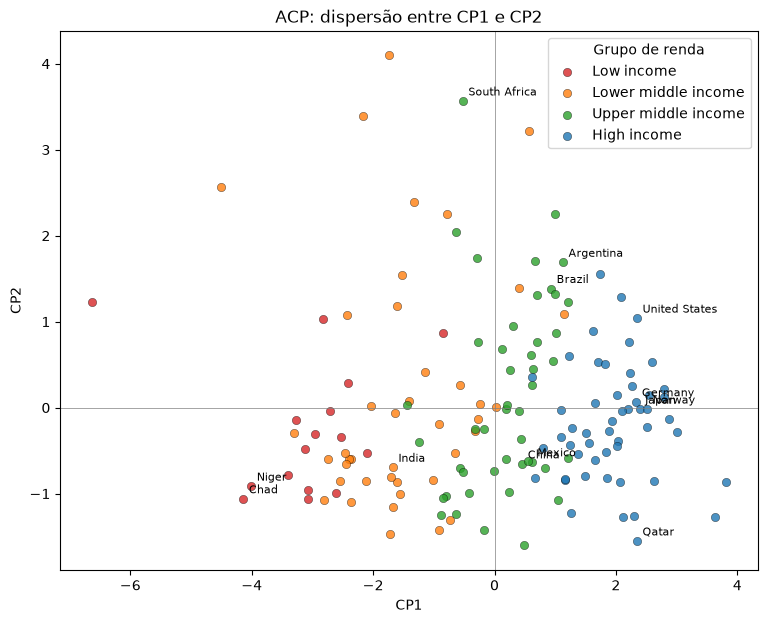

In [13]:
# Escores das componentes (variáveis padronizadas x autovetores)
escores = pd.DataFrame(Z.to_numpy() @ autovet[:, :3], index=dados.index, columns=["CP1", "CP2", "CP3"])
escores["renda"] = dados["renda"].values
escores["pais"] = dados["pais"].values

def grafico_grupos(ax, df, x, y, rotulos=None):
    for g in ordem_renda:
        s = df[df["renda"] == g]
        ax.scatter(s[x], s[y], c=cores[g], label=g, alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlabel(x); ax.set_ylabel(y)
    if rotulos is not None:
        for _, r in df[df["pais"].isin(rotulos)].iterrows():
            ax.annotate(r["pais"], (r[x], r[y]), textcoords="offset points", xytext=(4, 4), fontsize=8)

destaque = ["Brazil", "United States", "China", "India", "Nigeria", "Germany", "Japan",
            "Chad", "Norway", "Mexico", "Argentina", "South Africa", "Niger", "Qatar"]
fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, escores, "CP1", "CP2", destaque)
ax.legend(title="Grupo de renda"); ax.set_title("ACP: dispersão entre CP1 e CP2")
plt.show()

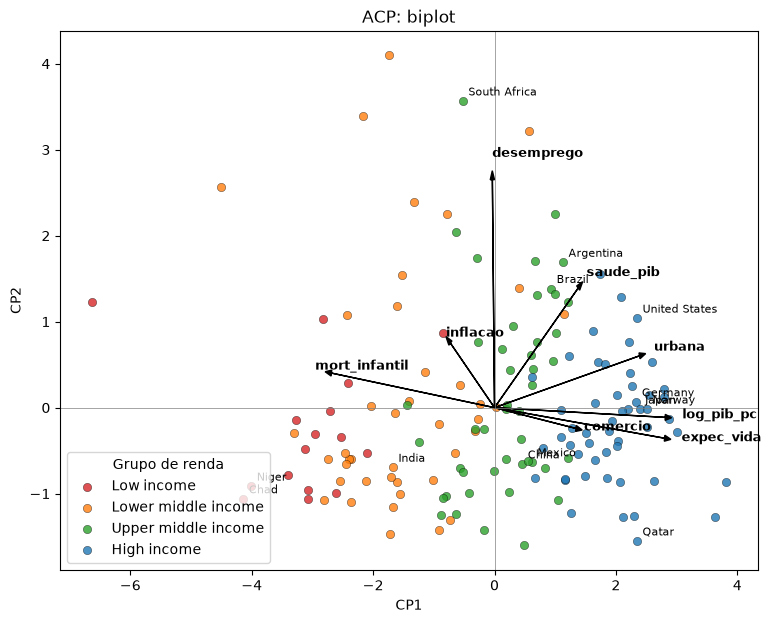

In [14]:
# Biplot (slides 52-54): países + setas das variáveis
fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, escores, "CP1", "CP2", destaque)
esc = 3.0
for nome, (a, b) in zip(vars_an, corr_cv):
    ax.arrow(0, 0, a * esc, b * esc, color="k", head_width=0.07)
    ax.text(a * esc * 1.1, b * esc * 1.1, nome, fontsize=9, weight="bold")
ax.legend(title="Grupo de renda", loc="lower left"); ax.set_title("ACP: biplot")
plt.show()

**Interpretação (para discutir em aula):** a primeira componente funciona como um *índice de desenvolvimento* (contrasta mortalidade infantil com PIB per capita, expectativa de vida e urbanização); a segunda componente é dominada pelo **desemprego** (correlação $\approx 0{,}88$) e, em menor grau, pelo gasto em saúde e pela inflação — ou seja, captura uma dimensão *distinta* do nível de desenvolvimento. Confirme nas correlações da tabela acima. Note que as duas primeiras componentes explicam apenas $\approx 60\%$ da variabilidade.

## 4. Escalonamento Multidimensional (ESM)

Aplicamos o ESM clássico (como no Exemplo 3) à matriz de **distâncias euclidianas** entre os países, calculadas sobre as variáveis padronizadas $Z$:
$$B = -\tfrac12 H D^{*} H, \qquad Y = Q_q \Lambda_q^{1/2}, \qquad \text{distor}(q) = \frac{\sum_{k\le q}|\lambda_k|}{\sum_k |\lambda_k|}.$$

In [15]:
def dist_euclid(Y):
    diff = Y[:, None, :] - Y[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1))

n = len(dados)
D = dist_euclid(Z.to_numpy())                 # matriz de distâncias n x n

def esm_classico(D):
    n = D.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * H @ (D ** 2) @ H
    lam, Q = np.linalg.eigh(B)
    o = np.argsort(lam)[::-1]
    return lam[o], Q[:, o]

lam, Q = esm_classico(D)
esm = lambda q: Q[:, :q] * np.sqrt(lam[:q])
distor = lambda q: np.abs(lam[:q]).sum() / np.abs(lam).sum()

def stress_kruskal(Y):
    d = dist_euclid(Y); iu = np.triu_indices(n, 1)
    return np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum())

print("Autovalores negativos de B:", int((lam < -1e-8).sum()), "(distâncias euclidianas => B semidefinida positiva)")
pd.DataFrame({"distor": [distor(q) for q in (2, 3)],
              "Stress (Kruskal)": [stress_kruskal(esm(q)) for q in (2, 3)]},
             index=["q = 2", "q = 3"]).round(4)

Autovalores negativos de B: 0 (distâncias euclidianas => B semidefinida positiva)


,distor,Stress (Kruskal)
q = 2,0.5994,0.3241
q = 3,0.7222,0.2093


### 4.1 ESM com $q = 2$

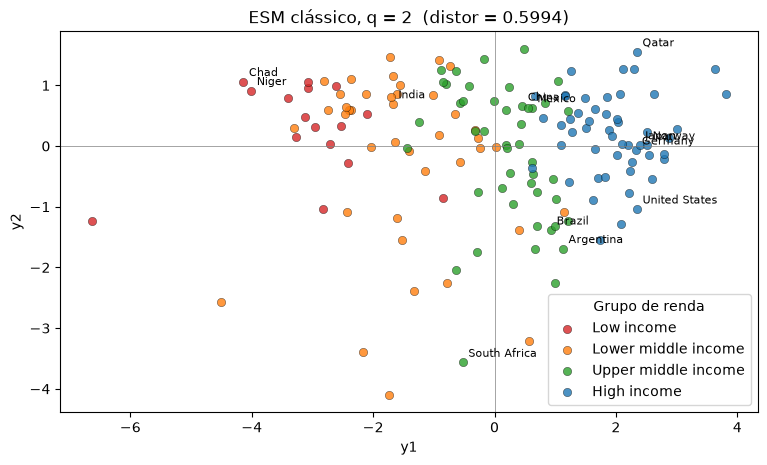

In [16]:
Y2 = esm(2)
mds2 = pd.DataFrame(Y2, index=dados.index, columns=["y1", "y2"])
mds2["renda"] = dados["renda"].values; mds2["pais"] = dados["pais"].values

fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, mds2, "y1", "y2", destaque)
ax.legend(title="Grupo de renda"); ax.set_aspect("equal")
ax.set_title(f"ESM clássico, q = 2  (distor = {distor(2):.4f})")
plt.show()

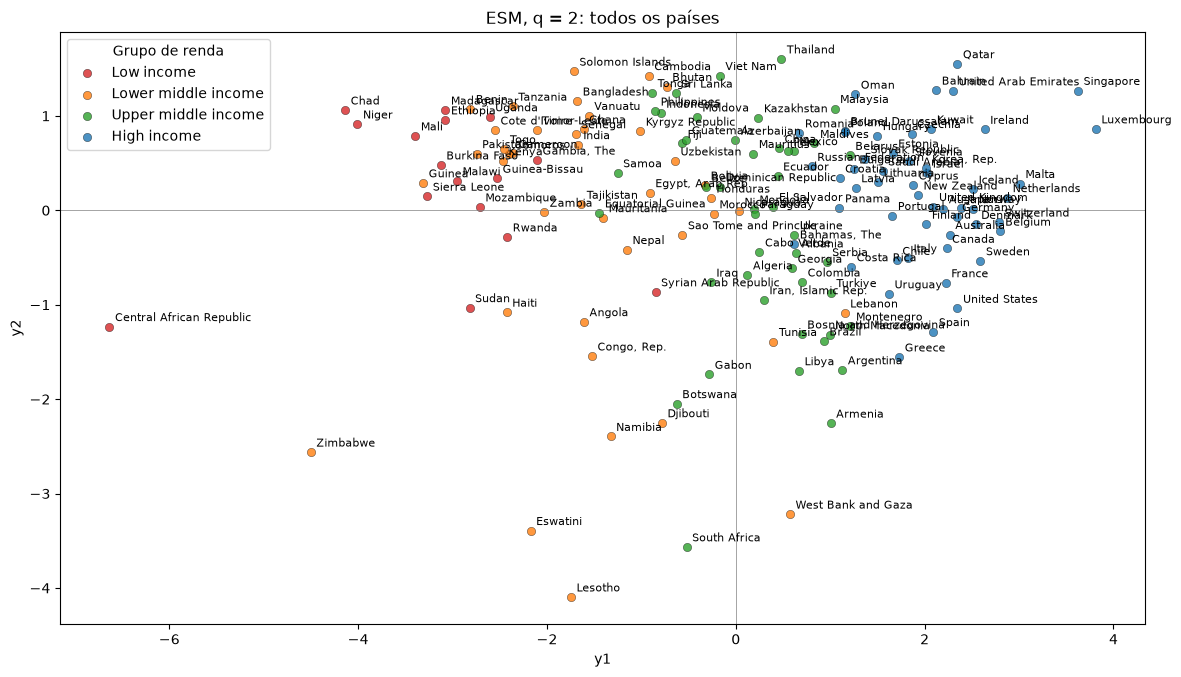

In [17]:
# Todos os países rotulados (versão para projetar/zoom)
fig, ax = plt.subplots(figsize=(14, 11))
grafico_grupos(ax, mds2, "y1", "y2", rotulos=list(mds2["pais"]))
ax.legend(title="Grupo de renda"); ax.set_aspect("equal")
ax.set_title("ESM, q = 2: todos os países")
plt.show()

### 4.2 ESM com $q = 3$

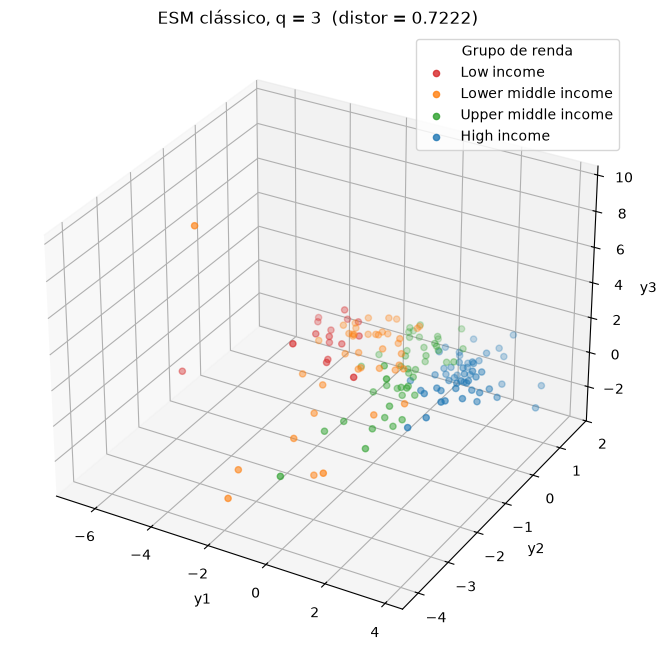

In [18]:
Y3 = esm(3)
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")
for g in ordem_renda:
    m = (dados["renda"] == g).to_numpy()
    ax.scatter(Y3[m, 0], Y3[m, 1], Y3[m, 2], c=cores[g], label=g, alpha=0.8)
ax.set_xlabel("y1"); ax.set_ylabel("y2"); ax.set_zlabel("y3")
ax.legend(title="Grupo de renda"); ax.set_title(f"ESM clássico, q = 3  (distor = {distor(3):.4f})")
plt.show()

## 5. ESM × ACP

Para dados padronizados e distância euclidiana, o ESM clássico e a ACP (pela matriz de correlações) fornecem **a mesma configuração**, a menos do sinal dos eixos. Consequentemente, a medida `distor` do ESM coincide com a porcentagem de variância explicada acumulada (PVEA) da ACP.

In [19]:
print("distor ESM (q=2) :", round(distor(2), 6), "| PVEA ACP (2 comp.):", round(tab["PVEA (%)"].iloc[1] / 100, 6))
print("distor ESM (q=3) :", round(distor(3), 6), "| PVEA ACP (3 comp.):", round(tab["PVEA (%)"].iloc[2] / 100, 6))

Yacp = Z.to_numpy() @ autovet[:, :3]
iguais = [np.allclose(np.abs(Y3[:, k]), np.abs(Yacp[:, k]), atol=1e-6) for k in range(3)]
print("Coordenadas do ESM = escores da ACP (|valor|), por componente:", iguais)

distor ESM (q=2) : 0.599375 | PVEA ACP (2 comp.): 0.599375
distor ESM (q=3) : 0.722249 | PVEA ACP (3 comp.): 0.722249
Coordenadas do ESM = escores da ACP (|valor|), por componente: [True, True, True]


In [20]:
# Os eixos podem diferir em sinal; alinhando-os, os gráficos coincidem
sinal = np.sign((Y2 * Yacp[:, :2]).sum(axis=0))
print("Sinais relativos entre ESM e ACP:", sinal)

Sinais relativos entre ESM e ACP: [ 1. -1.]


## 6. Comentários

- Pela heurística `distor` $> 0{,}70$, apenas $q=3$ ($\approx 0{,}72$) é satisfatório; com $q=2$, `distor` $\approx 0{,}60$ (as mesmas conclusões do Exemplo 3: o gráfico 2D é o mais fácil de interpretar, mas perde informação). Aqui os 8 indicadores não são redundantes (o desemprego, por exemplo, é pouco correlacionado com os demais), por isso a redução de dimensão é menos eficiente do que no Exemplo 4 ($0{,}87$ com $q=2$).
- O gradiente **renda baixa → renda alta** aparece ao longo de $y_1$; os grupos de renda adjacentes se sobrepõem bastante (a renda é uma classificação por faixas, não uma separação natural nos dados). A renda é um rótulo *não usado* na análise: a estrutura emerge dos indicadores.
- Como as distâncias são euclidianas, $B$ é semidefinida positiva (sem autovalores negativos), ao contrário do Exemplo 3 (distâncias geográficas na esfera).
- Cuidados: a padronização é essencial; valores extremos (por exemplo, inflação) podem distorcer as distâncias; o resultado depende do ano e do conjunto de indicadores escolhidos.
- Para dissimilaridades que não são distâncias euclidianas, existem versões não métricas (`MASS::isoMDS`, `MASS::sammon`; em Python, `sklearn.manifold.MDS(metric=False)`).